# Tools comparison

[W: Chinese Tools GenderGuesser](https://www.chinese-tools.com/tools/gender-guesser.html)

[R: ChineseNames R package](https://cran.r-project.org/web/packages/ChineseNames/ChineseNames.pdf)

[N: Namsor](https://namsor.app/)

In [1]:
import sys
sys.path.append('../libs')

%load_ext autoreload
%autoreload 2

import ios
import vis
import tools_comparison
from tools_comparison import ToolsComparison
import categorical
import constants

Total combinations of features: 1023


In [2]:
VERSION = 3

DIR_GT = f'../../data/v{VERSION}/annotations/gender'
DIR_RESULTS = f'../../results/v{VERSION}/'

DIR_NAMES = ios.path_join(DIR_RESULTS, 'names/chinese')
DIR_GENDER = ios.path_join(DIR_RESULTS, 'gender')

DIR_TOOL_W = ios.path_join(DIR_GENDER, 'tool_w')
DIR_TOOL_R = ios.path_join(DIR_GENDER, 'tool_r')
DIR_TOOL_N = ios.path_join(DIR_GENDER, 'tool_n')

DIR_PRED = ios.path_join(DIR_GENDER, 'predictions')
FN_GT = constants.FN_ANNOTATIONS

## Data

In [3]:
REMOVE_UNNECESSARY_NAMES = False  # Set to True to remove names that don't need to be in the GT

In [4]:
# Ground truth preparation (multiple files)
assert ToolsComparison.prepare_ground_truth(dir_gt=DIR_GT, fn_gt=FN_GT, 
                                            remove_unnecesary_names=REMOVE_UNNECESSARY_NAMES)


[INFO] Found 3 files in ../../data/v3/annotations/gender.
[2025-08-23 23:01:05] Reading ../../data/v3/annotations/gender/Chinese first names gender inference (Responses) - round 1.xlsx
[INFO] ../../data/v3/annotations/gender/Chinese first names gender inference (Responses) - round 1.xlsx has 11 columns and 100 rows (round 1).
[INFO] single_char
False    96
True      4
Name: count, dtype: int64
[2025-08-23 23:01:05] Reading ../../data/v3/annotations/gender/Chinese first names gender inference (Responses) - round 2.xlsx
[INFO] ../../data/v3/annotations/gender/Chinese first names gender inference (Responses) - round 2.xlsx has 11 columns and 48 rows (round 2).
[INFO] single_char
True     46
False     2
Name: count, dtype: int64
[2025-08-23 23:01:05] Reading ../../data/v3/annotations/gender/Chinese first names gender inference (Responses) - round 3.xlsx
[INFO] ../../data/v3/annotations/gender/Chinese first names gender inference (Responses) - round 3.xlsx has 11 columns and 18 rows (round 

In [5]:
tc = ToolsComparison(dir_tool_w=DIR_TOOL_W, dir_tool_r=DIR_TOOL_R, dir_tool_n=DIR_TOOL_N, dir_gt=DIR_GT, dir_names=DIR_NAMES,
                     remove_unnecesary_names=REMOVE_UNNECESSARY_NAMES) # @TODO: remove_unnecesary_names needs to be removed once we decided which GT to use 166 or 130

# If exists, load:
tc.load_tools_inference(DIR_PRED, tools_comparison.const.FN_CH_GIVEN_NAMES_GENDER) 

if tc.df_ch_genders_gt is None:
    # load all given names
    tc.load_data()
    # validate
    tc.validate_givennames()
    print(tc.df_givennames.givenname.nunique(), tc.df_givennames.single_char.nunique(), tc.df_gt.givenname.nunique(), tc.df_ch_gender_n.givenname.nunique(), tc.df_ch_gender_r.givenname.nunique(), tc.df_ch_gender_w.givenname.nunique())
    # create new gender features and standardize feature names based on tools
    tc.compare_unique_chinese_given_names(ignore_empty=True)
    # save data
    tc.save_tools_inference(DIR_PRED, tools_comparison.const.FN_CH_GIVEN_NAMES_GENDER)

# without removing unnecesary names
# 46144 166 46144 46144 38048
# (46144, 3) (46144, 3) (38048, 6)
# 166

# removing unnecesary names
# 46144 2 130 46144 46144 38048
# (46144, 3) (46144, 3) (38048, 6)
# 130

In [6]:
tc.df_ch_genders.head(2)

,givenname,ngender_r,gender_w,a1,a2,a3,a4,a5,a6,a7,...,std_ngender_rnw,std_ngender_rn,std_ngender_rw,std_ngender_nw,mode,mode_ngender_rnw,mode_ngender_rn,mode_ngender_rw,mode_ngender_nw,gender_nw
0,㑇,NaN,unknown,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.464531,male
1,㑊,NaN,unknown,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.464531,male


In [7]:
tc.df_ch_genders.query('gt==True')[['mean','median','mode']]

,mean,median,mode
94,0.166667,0.125,0.00
134,0.312500,0.250,0.25
184,0.458333,0.500,0.50
739,0.354167,0.500,0.50
1128,0.625000,0.625,0.75
...,...,...,...
45065,0.479167,0.500,0.75
45292,0.833333,1.000,1.00
45308,0.625000,0.750,0.75
45501,0.895833,1.000,1.00


In [8]:
tc.df_ch_genders_gt

,givenname,ngender_r,gender_w,a1,a2,a3,a4,a5,a6,a7,...,std_ngender_rnw,std_ngender_rn,std_ngender_rw,std_ngender_nw,mode,mode_ngender_rnw,mode_ngender_rn,mode_ngender_rw,mode_ngender_nw,gender_nw
0,东,0.15675,unknown,2.0,2.0,1.0,1.0,1.0,2.0,3.0,...,NaN,0.147578,NaN,NaN,0.00,0.15675,0.15675,0.15675,0.451906,male
1,习,0.34495,unknown,3.0,2.0,2.0,1.0,2.0,2.0,2.0,...,NaN,0.057801,NaN,NaN,0.25,0.34495,0.34495,0.34495,0.460552,male
2,仅,0.60040,unknown,3.0,3.0,2.0,3.0,3.0,3.0,3.0,...,NaN,0.027519,NaN,NaN,0.50,0.60040,0.60040,0.60040,0.545362,female
3,县,0.13905,unknown,3.0,3.0,1.0,2.0,3.0,3.0,3.0,...,NaN,0.206751,NaN,NaN,0.50,0.13905,0.13905,0.13905,0.552551,female
4,园,0.78480,unknown,4.0,4.0,3.0,4.0,3.0,4.0,3.0,...,NaN,0.124512,NaN,NaN,0.75,0.78480,0.78480,0.78480,0.535775,female
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
161,静平,0.66210,male,3.0,3.0,4.0,2.0,4.0,4.0,3.0,...,0.287439,0.061829,0.331050,0.269221,0.75,0.66210,0.66210,0.66210,0.538443,neutral
162,颖伶,0.90300,female,5.0,4.0,5.0,5.0,4.0,5.0,4.0,...,0.148681,0.127754,0.048500,0.176254,1.00,0.90300,0.90300,0.90300,0.647493,female
163,颖弢,0.50435,male,4.0,3.0,2.0,4.0,4.0,2.0,4.0,...,0.215827,0.057458,0.252175,0.194717,0.75,0.50435,0.50435,0.50435,0.389434,male
164,馨心,0.76760,female,5.0,5.0,5.0,5.0,5.0,5.0,5.0,...,0.183298,0.108247,0.116200,0.224447,1.00,0.76760,0.76760,0.76760,0.551107,female


### Quick stats GT

In [9]:
GENDER_LABEL_MAP = {'male': 'M', 'female': 'F', 'neutral': 'N', 'unknown': 'U', 'mostly_female':'mF', 'mostly_male':'mM'}
import matplotlib.colors as mcolors

# Define the colors for each category
DIV_COLORS = {
    "M": "#8B4513",    # SaddleBrown (dark brown)
    "mM": "#D2B48C",   # Tan (light brown)
    "N": "#7F7F7F",    # Neutral grey
    "mF": "#90EE90",   # Light green
    "F": "#006400",    # Dark green
    "U": "#E41A1C"     # Red (from ColorBrewer/tab-like palette)
}

def _barplot(data, cat_col, figsize=(3.5,1.5), order=None):
    import pandas as pd
    
    df = data.copy()
    df.loc[:,cat_col] = df[cat_col].map(GENDER_LABEL_MAP)
    if order is not None:
        df[cat_col] = pd.Categorical(df[cat_col], categories=order, ordered=True)
    
    vc = df[cat_col].value_counts(normalize=True).sort_index()
    ax = vc.plot.bar(figsize=figsize)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
    for i, v in enumerate(vc):
        ax.text(i, v + 0.01, f"{v:.1%}", ha='center', va='bottom', fontsize=10)
    ax.set_ylabel("Proportion")
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
def plot_gender_by_charlen(data, cat_col='gender_n', figsize=(3.5,1.5), order=None, **kargs):
    from matplotlib import cm
    import matplotlib.pyplot as plt
    import pandas as pd
    df = data.copy()
    df.loc[:,'single_char'] = df['single_char'].apply(lambda v: 'single-char' if v else 'two-char')
    df.loc[:,cat_col] = df[cat_col].map(GENDER_LABEL_MAP)
    if order is not None:
        df[cat_col] = pd.Categorical(df[cat_col], categories=order, ordered=True)
    # Group by single_char and gender_n, get normalized counts
    data = (
        df.groupby(['single_char', cat_col], observed=False)
        .size()
        .groupby(level=0)
        .apply(lambda x: x / x.sum())
        .unstack(fill_value=0)
    )
    if order is not None:
        data = data.reindex(order, axis=1)

    cmap = kargs.pop('cmap', None)
    if cmap:
        cmap = mcolors.ListedColormap(list(DIV_COLORS.values()), name="custom_divergent")

    ax = data.plot(kind='bar', stacked=False, rot=0, figsize=figsize, cmap=cmap)
    ax.set_xticklabels([data.index[0][0], data.index[1][0]], rotation=0)
    ax.set_ylabel('Proportion')
    ax.set_xlabel('')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    for p in ax.patches:
        height = p.get_height()
        if height > 0:
            ax.annotate(f"{height:.1%}", (p.get_x() + p.get_width() / 2, height),
                        ha='center', va='bottom', fontsize=10)
    ncol = kargs.pop('ncol', len(order))
    ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.02), ncol=ncol, fontsize=9, title=cat_col)
    plt.show()
    plt.close()

def plot_histogram(data, x_col, cat_col, bins=10, figsize=(3.5, 1.5)):
    import matplotlib.pyplot as plt
    import seaborn as sns
    import matplotlib.lines as mlines
    
    df = data.copy()
    df.loc[:,'single_char'] = df['single_char'].apply(lambda v: 'single-char' if v else 'two-char')
    # Assume df is your DataFrame and you already have the bar plot code
    fig, ax = plt.subplots(figsize=figsize)

    # Plot histogram for all data
    ax.hist(df[x_col], bins=bins, color='lightgray', alpha=1., label='All', density=True)

    # Overlay KDEs for each group
    ax2 = ax.twinx()  # Create a second y-axis for the KDEs
    for group, color in zip(df[cat_col].unique(), ['tab:purple', 'tab:brown']):
        sns.kdeplot(
            data=df[df[cat_col] == group][x_col],
            ax=ax2,
            label=group,
            color=color,
            linewidth=2,
            fill=True,
            alpha=0.3
        )

    ax.set_xlabel(x_col)
    ax.set_ylabel('Density')
    ax2.set_ylabel('KDE')
    # Combine legends from both axes
    # ... after plotting histogram and KDEs ...
    handles1, labels1 = ax.get_legend_handles_labels()
    handles2, labels2 = ax2.get_legend_handles_labels()

    # Replace KDE handles with Line2D objects for line markers
    line_colors = ['tab:purple', 'tab:brown']  # Use your actual colors
    line_handles = [
        mlines.Line2D([], [], color=color, linewidth=2, label=label)
        for color, label in zip(line_colors, labels2)
    ]

    # Combine histogram handle(s) and line handles
    ax.legend(handles1 + line_handles, labels1 + labels2, loc='upper right', fontsize=9)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax2.spines['top'].set_visible(False)
    ax2.spines['right'].set_visible(False)
    plt.show()
    plt.close()

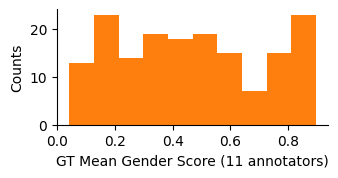

In [10]:
ax = tc.df_ch_genders_gt['mean'].hist(bins=10, figsize=(3.5,1.5), color='tab:orange')
ax.set_xlabel('GT Mean Gender Score (11 annotators)')
ax.set_ylabel('Counts')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(False)

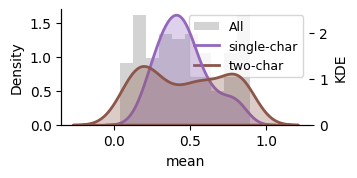

In [11]:
plot_histogram(tc.df_ch_genders_gt, x_col='mean', cat_col='single_char', bins=10, figsize=(3.2, 1.5))

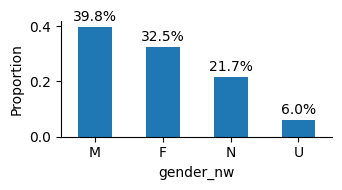

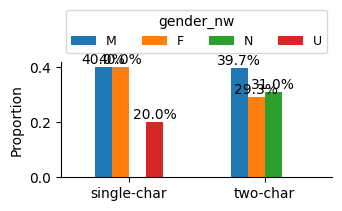

In [12]:
cat_col = 'gender_nw'
order = ['M','F','N','U']
_barplot(tc.df_ch_genders_gt, cat_col, figsize=(3.5,1.5), order=order)
plot_gender_by_charlen(tc.df_ch_genders_gt, cat_col, figsize=(3.5,1.5), order=order)

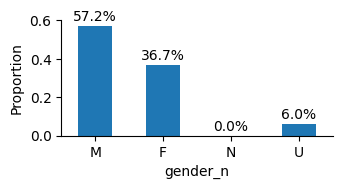

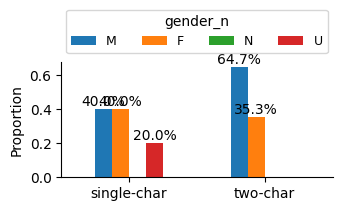

In [13]:
cat_col = 'gender_n'
_barplot(tc.df_ch_genders_gt, cat_col, figsize=(3.5,1.5), order=order)
plot_gender_by_charlen(tc.df_ch_genders_gt, cat_col, figsize=(3.5,1.5), order=order)


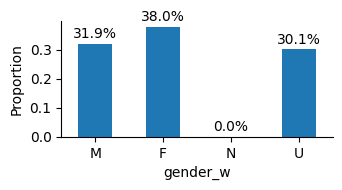

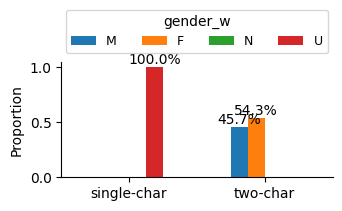

In [14]:
cat_col = 'gender_w'
_barplot(tc.df_ch_genders_gt, cat_col, figsize=(3.5,1.5), order=order)
plot_gender_by_charlen(tc.df_ch_genders_gt, cat_col, figsize=(3.5,1.5), order=order)

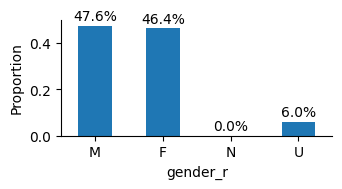

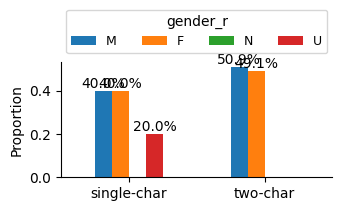

In [15]:
tmp = tc.df_ch_genders_gt.copy()
tmp.loc[:,'gender_r'] = tmp.ngender_r.apply(lambda v: categorical.UNKNOWN if tools_comparison.pd.isna(v) else 'female' if v>0.5 else 'male' if v<0.5 else 'neutral')

cat_col = 'gender_r'
_barplot(tmp, cat_col, figsize=(3.5,1.5), order=order)
plot_gender_by_charlen(tmp, cat_col, figsize=(3.5,1.5), order=order)

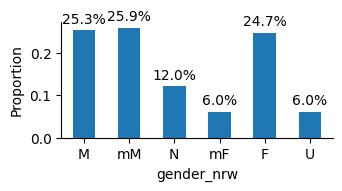

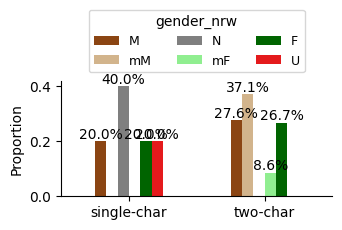

In [16]:
tmp = tc.df_ch_genders_gt.copy()
tmp.loc[:,'gender_r'] = tmp.ngender_r.apply(lambda v: categorical.UNKNOWN if tools_comparison.pd.isna(v) else 'female' if v>0.5 else 'male' if v<0.5 else 'neutral')

tmp.loc[:,'gender_nrw'] = tmp.apply(lambda row: 
                                                row.gender_n if row.gender_n == row.gender_r and row.gender_w == categorical.UNKNOWN and row.single_char else 
                                                row.gender_n if row.gender_n == row.gender_w and row.gender_n == row.gender_r else 
                                                categorical.MOSTLY_FEMALE if row.gender_n == row.gender_w and row.gender_n != row.gender_r and row.gender_n == categorical.FEMALE else 
                                                categorical.MOSTLY_FEMALE if row.gender_n == row.gender_r and row.gender_n != row.gender_w and row.gender_n == categorical.FEMALE else 
                                                categorical.MOSTLY_FEMALE if row.gender_r == row.gender_w and row.gender_r != row.gender_n and row.gender_n == categorical.FEMALE else
                                                categorical.MOSTLY_MALE if row.gender_n == row.gender_w and row.gender_n != row.gender_r and row.gender_n == categorical.MALE else 
                                                categorical.MOSTLY_MALE if row.gender_n == row.gender_r and row.gender_n != row.gender_w and row.gender_n == categorical.MALE else 
                                                categorical.MOSTLY_MALE if row.gender_r == row.gender_w and row.gender_r != row.gender_n and row.gender_n == categorical.MALE else
                                                categorical.NEUTRAL, axis=1)
cat_col = 'gender_nrw'
order_6 = ['M','mM','N','mF','F','U']
_barplot(tmp, cat_col, figsize=(3.5,1.5), order=order_6)
plot_gender_by_charlen(tmp, cat_col, figsize=(3.5,1.5), order=order_6, ncol=3, cmap=True)

In [17]:
tmp[['givenname','ngender_r','ngender_n','ngender_w','gender_n','gender_w','gender_r','single_char', 'gender_nrw']]

,givenname,ngender_r,ngender_n,ngender_w,gender_n,gender_w,gender_r,single_char,gender_nrw
0,东,0.15675,0.451906,NaN,male,unknown,male,True,male
1,习,0.34495,0.460552,NaN,male,unknown,male,True,male
2,仅,0.60040,0.545362,NaN,female,unknown,female,True,female
3,县,0.13905,0.552551,NaN,female,unknown,male,True,neutral
4,园,0.78480,0.535775,NaN,female,unknown,female,True,female
...,...,...,...,...,...,...,...,...,...
161,静平,0.66210,0.538443,0.0,female,male,female,False,mostly_female
162,颖伶,0.90300,0.647493,1.0,female,female,female,False,female
163,颖弢,0.50435,0.389434,0.0,male,male,female,False,mostly_male
164,馨心,0.76760,0.551107,1.0,female,female,female,False,female


## Overview

#### Categorical

In [18]:
FIGSIZE_SMALL = (5,3)

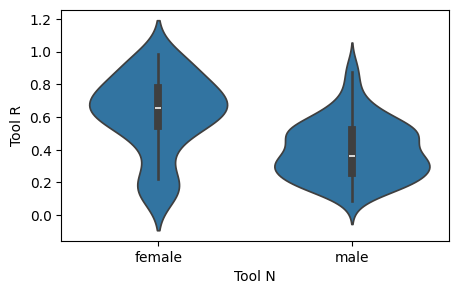

In [19]:
tool_y = 'r' # numerical
tool_x = 'n' # categorical
vis.plot_violin(df=tc.df_ch_genders_gt, x=f'gender_{tool_x}', y=f'ngender_{tool_y}', figsize=FIGSIZE_SMALL, 
                xlabel=f'Tool {tool_x.upper()}', 
                ylabel=f'Tool {tool_y.upper()}',
                kwargs_violin={'order': ['female', 'male']},
                )

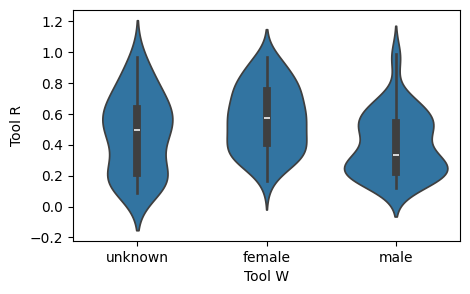

In [20]:
tool_y = 'r' # numerical
tool_x = 'w' # categorical
vis.plot_violin(df=tc.df_ch_genders_gt, x=f'gender_{tool_x}', y=f'ngender_{tool_y}', figsize=FIGSIZE_SMALL, 
                xlabel=f'Tool {tool_x.upper()}', 
                ylabel=f'Tool {tool_y.upper()}',
                )

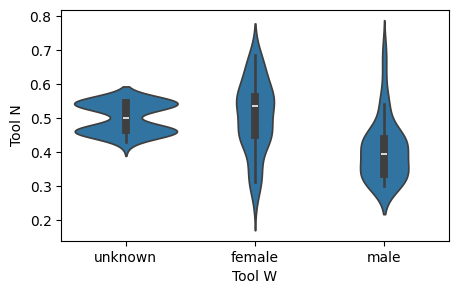

In [21]:
tool_y = 'n' # numerical
tool_x = 'w' # categorical
vis.plot_violin(df=tc.df_ch_genders_gt, x=f'gender_{tool_x}', y=f'ngender_{tool_y}', figsize=FIGSIZE_SMALL, 
                xlabel=f'Tool {tool_x.upper()}', 
                ylabel=f'Tool {tool_y.upper()}',
                )

#### Numerical

[Warning] Dropped 10 rows with NaN values
0.27157559531874814 0.3389595852373252


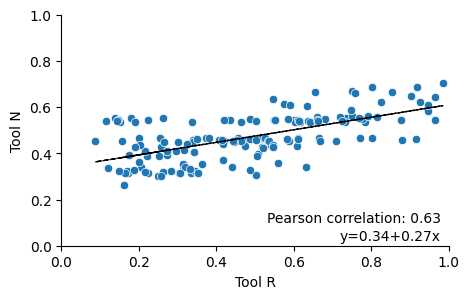

In [22]:
## scatter plot between namsor and R
tool_x = 'ngender_r'
tool_y = 'ngender_n'
vis.plot_scatter(data=tc.df_ch_genders_gt, x=tool_x, y=tool_y, figsize=(5, 3), 
                xlabel=f'Tool {tool_x.split('_')[-1].upper()}', 
                ylabel=f'Tool {tool_y.split('_')[-1].upper()}', 
                corr=True,
                fit=True,
                xlim=[0, 1], 
                ylim=[0, 1],
                )

## Index Performance

In [23]:
FIGSIZE = (3.5,3.1)
METRIC = 'mean' # GT

### Tool R

[Warning] Dropped 10 rows with NaN values
0.7584452833927453 0.13307027075003763


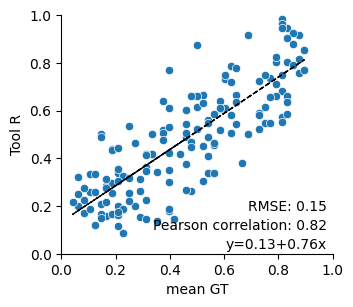

In [24]:
tool = 'r'
vis.plot_scatter(data=tc.df_ch_genders_gt, 
                 x=METRIC, y=f'ngender_{tool}', 
                 rmse=True, corr=True, fit=True,
                 xlim=[0, 1], 
                 ylim=[0, 1],
                 figsize=FIGSIZE, xlabel=f'{METRIC} GT', ylabel=f'Tool {tool.upper()}'
                 )

### Tool N

[Warning] Dropped 10 rows with NaN values
0.2901915723360947 0.3359029834795755


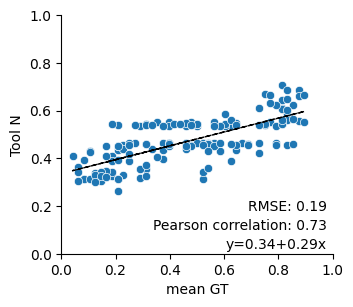

In [25]:
tool = 'n'
vis.plot_scatter(data=tc.df_ch_genders_gt, 
                 x=METRIC, y=f'ngender_{tool}', 
                 rmse=True, corr=True, fit=True,
                 xlim=[0, 1], 
                 ylim=[0, 1],
                 figsize=FIGSIZE, xlabel=f'{METRIC} GT', ylabel=f'Tool {tool.upper()}', 
                 )


### Tool RNW 

[Warning] Dropped 50 rows with NaN values
0.6520290154775347 0.19320534647542567


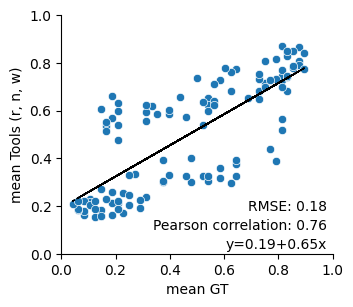

In [26]:
tools = 'rnw'
column = f'{METRIC}_ngender_{tools}'

vis.plot_scatter(data=tc.df_ch_genders_gt, 
                 x=METRIC, y=column,
                 rmse=True, corr=True, fit=True,
                 xlim=[0, 1], 
                 ylim=[0, 1],
                 figsize=FIGSIZE, xlabel=f'{METRIC} GT', ylabel=f'{METRIC} Tools ({', '.join(tools)})',
                 )

### Tool RN

[Warning] Dropped 10 rows with NaN values
0.5243184278644201 0.23448662711480653


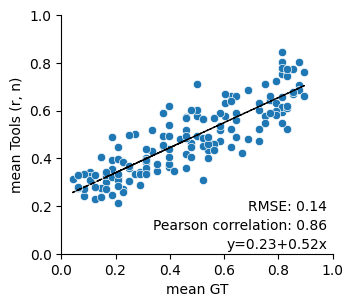

In [27]:
tools = 'rn'
column = f'{METRIC}_ngender_{tools}'

vis.plot_scatter(data=tc.df_ch_genders_gt, 
                 x=METRIC, y=column,
                 rmse=True, corr=True, fit=True,
                 xlim=[0, 1], 
                 ylim=[0, 1],
                 figsize=FIGSIZE, xlabel=f'{METRIC} GT', ylabel=f'{METRIC} Tools ({', '.join(tools)})',
                 )

### Tool RW

[Warning] Dropped 50 rows with NaN values
0.8164694379873394 0.13522748645923016


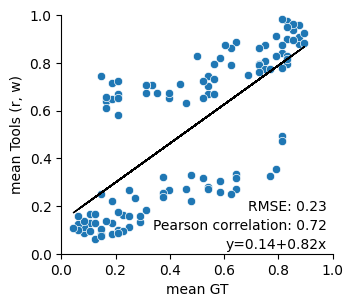

In [28]:
tools = 'rw'
column = f'{METRIC}_ngender_{tools}'

vis.plot_scatter(data=tc.df_ch_genders_gt, 
                 x=METRIC, y=column,
                 rmse=True, corr=True, fit=True,
                 xlim=[0, 1], 
                 ylim=[0, 1],
                 figsize=FIGSIZE, xlabel=f'{METRIC} GT', ylabel=f'{METRIC} Tools ({', '.join(tools)})', 
                 )


### Tool NW

[Warning] Dropped 50 rows with NaN values
0.6262381556975336 0.20865478475514843


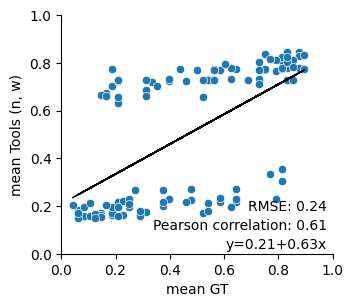

In [29]:
tools = 'nw'
column = f'{METRIC}_ngender_{tools}'

vis.plot_scatter(data=tc.df_ch_genders_gt, 
                 x=METRIC, y=column,
                 rmse=True, corr=True, fit=True,
                 xlim=[0, 1], 
                 ylim=[0, 1],
                 figsize=FIGSIZE, xlabel=f'{METRIC} GT', ylabel=f'{METRIC} Tools ({', '.join(tools)})',
                 )

## Categorical Splits

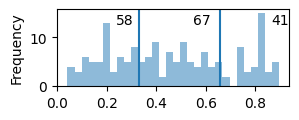

In [30]:
# 1. equal-width bins
cuts_1 = 'mean', [0.33, 0.66]
vis.plot_distribution_and_cuts(tc.df_ch_genders_gt, cuts_1[0], bins=30, figsize=(3,1), cuts=cuts_1[1]) 

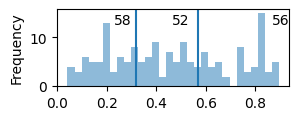

In [31]:
# 2. equal-size bins
cuts_2 = 'mean', [0.33, 0.55] if REMOVE_UNNECESSARY_NAMES else [0.32, 0.57]
vis.plot_distribution_and_cuts(tc.df_ch_genders_gt, cuts_2[0], bins=30, figsize=(3,1), cuts=cuts_2[1])

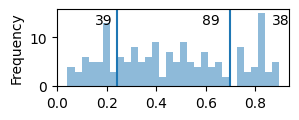

In [32]:
# 3. visual groups
cuts_3 = 'mean', [0.26, 0.70] if REMOVE_UNNECESSARY_NAMES else [0.24, 0.70]

vis.plot_distribution_and_cuts(tc.df_ch_genders_gt, cuts_3[0], bins=30, figsize=(3,1), cuts=cuts_3[1])

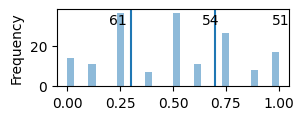

In [33]:
# 4. median visual groups
cuts_4 = 'median', [0.3, 0.7] 
vis.plot_distribution_and_cuts(tc.df_ch_genders_gt, cuts_4[0], bins=30, figsize=(3,1), cuts=cuts_4[1])

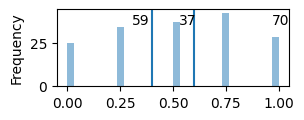

In [34]:
# 5. mode visual groups
cuts_5 = 'mode', [0.4, 0.6] 
vis.plot_distribution_and_cuts(tc.df_ch_genders_gt, cuts_5[0], bins=30, figsize=(3,1), cuts=cuts_5[1])

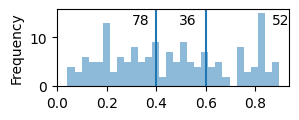

In [36]:
# 6. cuts from survey
cuts_6 = 'mean', [0.4, 0.6] 
vis.plot_distribution_and_cuts(tc.df_ch_genders_gt, cuts_6[0], bins=30, figsize=(3,1), cuts=cuts_6[1])

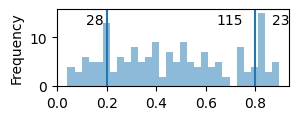

In [38]:
# 7. cuts from survey
cuts_7 = 'mean', [0.2, 0.8] 
vis.plot_distribution_and_cuts(tc.df_ch_genders_gt, cuts_7[0], bins=30, figsize=(3,1), cuts=cuts_7[1])

### Same thresholds for both GT and tools

In [108]:
STRATEGY = {1:{'name':'arbitrary_cuts', 'gt_gender':f'gender_{cuts_1[0]}', 'cuts':cuts_1[1]},
            2:{'name':'arbitrary_cuts', 'gt_gender':f'gender_{cuts_2[0]}', 'cuts':cuts_2[1]},
            3:{'name':'arbitrary_cuts', 'gt_gender':f'gender_{cuts_3[0]}', 'cuts':cuts_3[1]},
            4:{'name':'arbitrary_cuts', 'gt_gender':f'gender_{cuts_4[0]}', 'cuts':cuts_4[1]},
            5:{'name':'arbitrary_cuts', 'gt_gender':f'gender_{cuts_5[0]}', 'cuts':cuts_5[1]},
            6:{'name':'arbitrary_cuts', 'gt_gender':f'gender_{cuts_6[0]}', 'cuts':cuts_6[1]},
            7:{'name':'arbitrary_cuts', 'gt_gender':f'gender_{cuts_7[0]}', 'cuts':cuts_7[1]},
           }
STRATEGY

{1: {'name': 'arbitrary_cuts',
  'gt_gender': 'gender_mean',
  'cuts': [0.33, 0.66]},
 2: {'name': 'arbitrary_cuts',
  'gt_gender': 'gender_mean',
  'cuts': [0.32, 0.57]},
 3: {'name': 'arbitrary_cuts',
  'gt_gender': 'gender_mean',
  'cuts': [0.24, 0.7]},
 4: {'name': 'arbitrary_cuts',
  'gt_gender': 'gender_median',
  'cuts': [0.3, 0.7]},
 5: {'name': 'arbitrary_cuts', 'gt_gender': 'gender_mode', 'cuts': [0.4, 0.6]},
 6: {'name': 'arbitrary_cuts', 'gt_gender': 'gender_mean', 'cuts': [0.4, 0.6]},
 7: {'name': 'arbitrary_cuts', 'gt_gender': 'gender_mean', 'cuts': [0.2, 0.8]}}

In [104]:
STRATEGY_ID = 3

In [105]:

cuts = STRATEGY[STRATEGY_ID]['cuts']
gt_gender = STRATEGY[STRATEGY_ID]['gt_gender']
thresholds = [(-1,cuts[0]),(cuts[0],cuts[1]),(cuts[1],2)]
labels = categorical.GENDER_LABELS_3

df_sa = categorical.convert_numeric_to_categorical_by_thresholds(tc.df_ch_genders_gt, 
                                                                 thresholds=thresholds, 
                                                                 labels=labels)

df_comparison = categorical.comparison_metrics(df_sa,
                                               col_true=gt_gender, 
                                               labels=labels,
                                               cols_pred=['gender_r', 'gender_w', 'gender_n',
                                                          'gender_rn', 'gender_rw', 'gender_nw', 'gender_rnw',
                                                          'gender_mv_x1', 'gender_mv_x2', 'gender_mv_x1x2', 'gender_mv_all'])
df_comparison


/home/espinl/.conda/envs/py12chinam/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/espinl/.conda/envs/py12chinam/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


,gender_mean,gender_r,gender_w,gender_n,gender_rn,gender_rw,gender_nw,gender_rnw,gender_mv_x1,gender_mv_x2,gender_mv_x1x2,gender_mv_all
precision,"[1.0, 1.0, 1.0]","[0.94, 0.55, 0.86]","[0.49, 0.0, 0.46]","[0.47, 0.0, 0.68]","[1.0, 0.47, 1.0]","[0.76, 0.66, 0.6]","[0.57, 0.44, 0.54]","[0.85, 0.63, 0.8]","[0.58, 0.65, 0.76]","[0.78, 0.66, 0.63]","[0.76, 0.74, 0.65]","[0.76, 0.72, 0.78]"
recall,"[1.0, 1.0, 1.0]","[0.42, 0.91, 0.58]","[0.72, 0.0, 0.88]","[0.97, 0.0, 0.85]","[0.11, 1.0, 0.36]","[0.69, 0.49, 0.88]","[0.72, 0.15, 0.88]","[0.64, 0.79, 0.73]","[0.78, 0.43, 0.85]","[0.69, 0.53, 0.88]","[0.72, 0.53, 0.94]","[0.72, 0.7, 0.85]"
f1,"[1.0, 1.0, 1.0]","[0.58, 0.69, 0.69]","[0.58, 0.0, 0.6]","[0.63, 0.0, 0.76]","[0.2, 0.64, 0.53]","[0.72, 0.56, 0.72]","[0.63, 0.22, 0.67]","[0.73, 0.7, 0.76]","[0.67, 0.51, 0.8]","[0.74, 0.59, 0.73]","[0.74, 0.62, 0.77]","[0.74, 0.71, 0.81]"
auc,"[1.0, 1.0, 1.0]","[0.7, 0.7, 0.77]","[0.69, 0.5, 0.73]","[0.74, 0.5, 0.85]","[0.56, 0.62, 0.68]","[0.8, 0.66, 0.82]","[0.74, 0.51, 0.79]","[0.79, 0.73, 0.83]","[0.76, 0.63, 0.87]","[0.8, 0.67, 0.84]","[0.81, 0.7, 0.87]","[0.81, 0.76, 0.88]"
accuracy,1.0,0.66,0.47,0.54,0.54,0.66,0.53,0.72,0.66,0.68,0.71,0.75
mean_precision,1.0,0.78,0.32,0.38,0.82,0.67,0.51,0.76,0.66,0.69,0.72,0.75
mean_recall,1.0,0.64,0.53,0.61,0.49,0.69,0.58,0.72,0.68,0.7,0.73,0.76
mean_f1,1.0,0.65,0.4,0.46,0.46,0.67,0.51,0.73,0.66,0.69,0.71,0.75
mean_auc,1.0,0.73,0.64,0.69,0.62,0.76,0.68,0.79,0.76,0.77,0.79,0.81
n_male,36,16,53,75,4,33,46,27,48,32,34,34


In [106]:
BEST_F1 = {1:'gender_r',
           2:'gender_r',
           3:'gender_mv_all',
           4:'gender_rnw',
           5:'gender_r',
           6:'gender_rn',
           7:'gender_mv_all',}

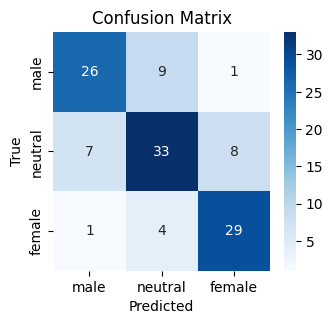

[0.76470588 0.7173913  0.76315789] [0.72222222 0.6875     0.85294118] [0.74285714 0.70212766 0.80555556] [0.81233062 0.75089286 0.87289916] 0.7457627118644068
0.75


In [107]:


col_pred = BEST_F1[STRATEGY_ID]
normalize = None

cm, precision, recall, f1, auc, accuracy = categorical.get_performance(df_sa, 
                                                                       col_true=gt_gender, 
                                                                       col_pred=col_pred, 
                                                                       labels=labels, 
                                                                       normalize=normalize)
vis.plot_confusion_matrix(cm, labels, title='Confusion Matrix', cmap='Blues', figsize=FIGSIZE)
print(precision, recall, f1, auc, accuracy)
print(tools_comparison.np.mean(f1).round(2))

In [103]:
_summary = {1: 0.68,
            2: 0.69,
            3: 0.75,
            4: 0.72,
            5: 0.59,
            6: 0.71,
            7: 0.71,
 }

best_strategy = max(_summary, key=_summary.get)
best_strategy, STRATEGY[best_strategy]

(3,
 {'name': 'arbitrary_cuts', 'gt_gender': 'gender_mean', 'cuts': [0.24, 0.7]})

### Different thresholds for  GT and tools

In [ ]:
ys = {'r':  [0.1629132932675171, 0.7182416961523954],
      'n':  [0.33920220560098047, 0.32376522953442416],
      'rnw':[0.19485861726436837, 0.6750024992414795],
      'rn': [0.25105774943424886, 0.5210034628434099],
      'rw': [0.12268682309606231, 0.8506211340950072],
      'nw': [0.21083127926279407, 0.6533829007860216]}

y = lambda x, tool: ys[tool][0] + (ys[tool][1] * x)
new_thresholds = lambda tool, thresholds: [(y(low,tool),y(high,tool)) for (low,high) in thresholds]

In [ ]:
df_eq = categorical.convert_numeric_to_categorical_by_thresholds(tc.df_ch_genders_gt, 
                                                                 thresholds=thresholds, 
                                                                 labels=labels, 
                                                                 new_trhesholds_fnc=new_thresholds,
                                                                 )

df_comparison_eq = categorical.comparison_metrics(df_eq,
                                                  col_true=gt_gender, 
                                                  labels=labels,
                                                  cols_pred=['gender_r', 'gender_w', 'gender_n',
                                                             'gender_rn', 'gender_rw', 'gender_nw', 'gender_rnw',
                                                             'gender_mv_x1', 'gender_mv_x2', 'gender_mv_x1x2', 'gender_mv_all'])
df_comparison_eq


In [ ]:
col_pred = 'gender_mv_x1x2'
cm, precision, recall, f1, auc, accuracy = categorical.get_performance(df_eq, 
                                                                       col_true=gt_gender, 
                                                                       col_pred=col_pred, 
                                                                       labels=labels, 
                                                                       normalize=normalize)
vis.plot_confusion_matrix(cm, labels, title='Confusion Matrix (equivalent thresholds)', cmap='Reds', figsize=FIGSIZE)
print(precision, recall, f1, auc, accuracy)

# Features

In [3]:
## Features
import sys
sys.path.append('../libs')

%load_ext autoreload
%autoreload 2

import setup
setup.FEATURES

Total combinations of features: 1023


['ngender_r',
 'ngender_n',
 'gender_n',
 'gender_w',
 'gender_nw',
 'single_char',
 'mean_ngender_rn',
 'mean_ngender_rw',
 'mean_ngender_nw',
 'mean_ngender_rnw']

In [ ]:
from itertools import combinations

items = setup.FEATURES
all_combinations = []

# Generate combinations of different sizes
for r in range(1, len(items) + 1):
    for comb in combinations(items, r):
        # Exclude combinations that contain both "item 8" and "item 10"
        if not ("ngender_n" in comb and "gender_n" in comb):
            all_combinations.append(list(comb))

# Print the number of combinations
print("Total combinations:", len(all_combinations))

# Print all combinations
for comb in all_combinations:
    print(comb)

    # 511 total (388 without the ngender_n, gender_n)


Total combinations: 767
['ngender_r']
['ngender_n']
['gender_n']
['gender_w']
['gender_nw']
['single_char']
['mean_ngender_rn']
['mean_ngender_rw']
['mean_ngender_nw']
['mean_ngender_rnw']
['ngender_r', 'ngender_n']
['ngender_r', 'gender_n']
['ngender_r', 'gender_w']
['ngender_r', 'gender_nw']
['ngender_r', 'single_char']
['ngender_r', 'mean_ngender_rn']
['ngender_r', 'mean_ngender_rw']
['ngender_r', 'mean_ngender_nw']
['ngender_r', 'mean_ngender_rnw']
['ngender_n', 'gender_w']
['ngender_n', 'gender_nw']
['ngender_n', 'single_char']
['ngender_n', 'mean_ngender_rn']
['ngender_n', 'mean_ngender_rw']
['ngender_n', 'mean_ngender_nw']
['ngender_n', 'mean_ngender_rnw']
['gender_n', 'gender_w']
['gender_n', 'gender_nw']
['gender_n', 'single_char']
['gender_n', 'mean_ngender_rn']
['gender_n', 'mean_ngender_rw']
['gender_n', 'mean_ngender_nw']
['gender_n', 'mean_ngender_rnw']
['gender_w', 'gender_nw']
['gender_w', 'single_char']
['gender_w', 'mean_ngender_rn']
['gender_w', 'mean_ngender_rw']
['

___

# OLD

#### Majority voting (tools)

In [ ]:
tool = 'r'
column = f'ngender_{tool}'
n_categories = 2
labels = GENDER_LABELS_2

tc.df_ch_genders_gt.loc[:,f'gender_{tool}'] = tools_comparison.pd.cut(tc.df_ch_genders_gt[column], bins=n_categories, labels=labels, right=True, precision=2, include_lowest=True)


# tc.df_ch_genders_gt.loc[:,f'majority_voting_nrw'] = tools_comparison.get_majority_voting(tc.df_ch_genders_gt, ['gender','',''], n_categories)
tc.df_ch_genders_gt.loc[:,'gender_rnw'] = tc.df_ch_genders_gt.apply(lambda row: row['gender_n'] if row['gender_n'] == row['gender_w'] and row['gender_n'] == row['gender_r'] else 
                                                                                f"mostly_{row['gender_n']}" if row['gender_n'] == row['gender_w'] else
                                                                                f"mostly_{row['gender_n']}" if row['gender_n'] == row['gender_r'] else
                                                                                f"mostly_{row['gender_r']}" if row['gender_r'] == row['gender_w'] else NEUTRAL, axis=1)

In [ ]:
tools = 'rnw'
column = f'{METRIC}_ngender_{tools}'

vis.plot_scatter(df=tc.df_ch_genders_gt, 
                 x=METRIC, y=column,
                 hue='gender_rnw',
                 rmse=True, corr=True, fit=True,
                 xlim=[0, 1], 
                 ylim=[0, 1],
                 figsize=FIGSIZE, xlabel=f'{METRIC} GT', ylabel=f'{METRIC} Tools ({', '.join(tools)})',
                 )


In [ ]:
# # get evaluation metrics
auc, precision, recall, accuracy, fpr, tpr, cm_raw, cm_recall, cm_precision, gender_labels = tc.get_performance_general(column=column, metric=metric, labels_fnc=labels_fnc, 
                                                                                                                        bins_gt = bins_x,
                                                                                                                        bins_tools = bins_y)

# plot roc auc
vis.plot_roc_auc(auc, fpr, tpr, gender_labels, figsize=FIGSIZE)

# # plot confusion matrix (raw)
vis.plot_confusion_matrix(cm_raw, gender_labels, title='Confusion Matrix (raw)', cmap='Blues', figsize=FIGSIZE)

# # plot confusion matrix (recall-row)
vis.plot_confusion_matrix(cm_recall, gender_labels, title='Confusion Matrix (recall-row)', cmap='Blues', figsize=FIGSIZE)

# # plot confusion matrix (precision-col)
vis.plot_confusion_matrix(cm_precision, gender_labels, title='Confusion Matrix (precision-col)', cmap='Blues', figsize=FIGSIZE)

### Per tool

##### Tool R

In [ ]:
column = 'ngender_r'
get_label_fnc = get_label_3classes

best_thresholds, log_auc_rmse = tc.get_best_thresholds_general(column=column, metric=METRIC, labels_fnc=get_label_fnc)
print(best_thresholds)

# get evaluation metrics
auc, precision, recall, accuracy, fpr, tpr, cm_raw, cm_recall, cm_precision, gender_labels = tc.get_performance_general(column=column, metric=METRIC, labels_fnc=get_label_fnc, thresholds=best_thresholds)

# plot roc auc
vis.plot_roc_auc(auc, fpr, tpr, gender_labels, figsize=figsize)

# plot confusion matrix (raw)
vis.plot_confusion_matrix(cm_raw, gender_labels, title='Confusion Matrix (raw)', cmap='Blues', figsize=figsize)

# plot confusion matrix (recall-row)
vis.plot_confusion_matrix(cm_recall, gender_labels, title='Confusion Matrix (recall-row)', cmap='Blues', figsize=figsize)

# plot confusion matrix (precision-col)
vis.plot_confusion_matrix(cm_precision, gender_labels, title='Confusion Matrix (precision-col)', cmap='Blues', figsize=figsize)

In [ ]:
column = 'ngender_r'
get_label_fnc = get_label_5classes

best_thresholds, log_auc_rmse = tc.get_best_thresholds_general(column=column, metric=METRIC, labels_fnc=get_label_fnc)
print(best_thresholds)

# get evaluation metrics
auc, precision, recall, accuracy, fpr, tpr, cm_raw, cm_recall, cm_precision, gender_labels = tc.get_performance_general(column=column, metric=METRIC, labels_fnc=get_label_fnc, thresholds=best_thresholds)

# plot roc auc
vis.plot_roc_auc(auc, fpr, tpr, gender_labels, figsize=figsize)

# plot confusion matrix (raw)
vis.plot_confusion_matrix(cm_raw, gender_labels, title='Confusion Matrix (raw)', cmap='Blues', figsize=figsize)

# plot confusion matrix (recall-row)
vis.plot_confusion_matrix(cm_recall, gender_labels, title='Confusion Matrix (recall-row)', cmap='Blues', figsize=figsize)

# plot confusion matrix (precision-col)
vis.plot_confusion_matrix(cm_precision, gender_labels, title='Confusion Matrix (precision-col)', cmap='Blues', figsize=figsize)

##### Tools RN

In [ ]:
tools = 'rn'
column = f'{METRIC}_ngender_{tools}'
get_label_fnc = get_label_3classes

best_thresholds, log_auc_rmse = tc.get_best_thresholds_general(column=column, metric=METRIC, labels_fnc=get_label_fnc)
print(best_thresholds)

# get evaluation metrics
auc, precision, recall, accuracy, fpr, tpr, cm_raw, cm_recall, cm_precision, gender_labels = tc.get_performance_general(column=column, metric=METRIC, labels_fnc=get_label_fnc, thresholds=best_thresholds)

# plot roc auc
vis.plot_roc_auc(auc, fpr, tpr, gender_labels, figsize=figsize)

# plot confusion matrix (raw)
vis.plot_confusion_matrix(cm_raw, gender_labels, title='Confusion Matrix (raw)', cmap='Blues', figsize=figsize)

# plot confusion matrix (recall-row)
vis.plot_confusion_matrix(cm_recall, gender_labels, title='Confusion Matrix (recall-row)', cmap='Blues', figsize=figsize)

# plot confusion matrix (precision-col)
vis.plot_confusion_matrix(cm_precision, gender_labels, title='Confusion Matrix (precision-col)', cmap='Blues', figsize=figsize)

In [ ]:
tools = 'rn'
column = f'{METRIC}_ngender_{tools}'
get_label_fnc = get_label_5classes

best_thresholds, log_auc_rmse = tc.get_best_thresholds_general(column=column, metric=METRIC, labels_fnc=get_label_fnc)
print(best_thresholds)

# get evaluation metrics
auc, precision, recall, accuracy, fpr, tpr, cm_raw, cm_recall, cm_precision, gender_labels = tc.get_performance_general(column=column, metric=METRIC, labels_fnc=get_label_fnc, thresholds=best_thresholds)

# plot roc auc
vis.plot_roc_auc(auc, fpr, tpr, gender_labels, figsize=figsize)

# plot confusion matrix (raw)
vis.plot_confusion_matrix(cm_raw, gender_labels, title='Confusion Matrix (raw)', cmap='Blues', figsize=figsize)

# plot confusion matrix (recall-row)
vis.plot_confusion_matrix(cm_recall, gender_labels, title='Confusion Matrix (recall-row)', cmap='Blues', figsize=figsize)

# plot confusion matrix (precision-col)
vis.plot_confusion_matrix(cm_precision, gender_labels, title='Confusion Matrix (precision-col)', cmap='Blues', figsize=figsize)

##### Tools RNW
all three

In [ ]:
tools = 'rnw'
column = f'{METRIC}_ngender_{tools}'
get_label_fnc = get_label_3classes

best_thresholds = tc.get_best_thresholds_general(column=column, metric=METRIC, labels_fnc=get_label_fnc)
print(best_thresholds)

# get evaluation metrics
auc, precision, recall, accuracy, fpr, tpr, cm_raw, cm_recall, cm_precision, gender_labels = tc.get_performance_general(column=column, metric=METRIC, labels_fnc=get_label_fnc, thresholds=best_thresholds)

# plot roc auc
vis.plot_roc_auc(auc, fpr, tpr, gender_labels, figsize=figsize)

# plot confusion matrix (raw)
vis.plot_confusion_matrix(cm_raw, gender_labels, title='Confusion Matrix (raw)', cmap='Blues', figsize=figsize)

# plot confusion matrix (recall-row)
vis.plot_confusion_matrix(cm_recall, gender_labels, title='Confusion Matrix (recall-row)', cmap='Blues', figsize=figsize)

# plot confusion matrix (precision-col)
vis.plot_confusion_matrix(cm_precision, gender_labels, title='Confusion Matrix (precision-col)', cmap='Blues', figsize=figsize)

In [ ]:
tools = 'rnw'
column = f'{METRIC}_ngender_{tools}'
get_label_fnc = get_label_5classes

best_thresholds = tc.get_best_thresholds_general(column=column, metric=METRIC, labels_fnc=get_label_fnc)
print(best_thresholds)

# get evaluation metrics
auc, precision, recall, accuracy, fpr, tpr, cm_raw, cm_recall, cm_precision, gender_labels = tc.get_performance_general(column=column, metric=METRIC, labels_fnc=get_label_fnc, thresholds=best_thresholds)

# plot roc auc
vis.plot_roc_auc(auc, fpr, tpr, gender_labels, figsize=figsize)

# plot confusion matrix (raw)
vis.plot_confusion_matrix(cm_raw, gender_labels, title='Confusion Matrix (raw)', cmap='Blues', figsize=figsize)

# plot confusion matrix (recall-row)
vis.plot_confusion_matrix(cm_recall, gender_labels, title='Confusion Matrix (recall-row)', cmap='Blues', figsize=figsize)

# plot confusion matrix (precision-col)
vis.plot_confusion_matrix(cm_precision, gender_labels, title='Confusion Matrix (precision-col)', cmap='Blues', figsize=figsize)